### <font color='gold'> Import les librairies requises

In [1]:
# Importer  packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
 # Supprimer les warnings
 import warnings
 warnings.filterwarnings('ignore')

###<font color='gold'> Importer et lire les données

In [3]:
# Importer data
df = pd.read_csv('Customer_dataset.csv')


#### Description des variables du jeu de données "Télécommunications"

Ce jeu de données contient des informations sur le comportement et les caractéristiques des clients d'une entreprise de télécommunications. L'objectif est d'effectuer une segmentation (clustering) des clients pour identifier des groupes homogènes.

| Variable | Type | Description |
|----------|------|-------------|
| `Call Failure` | Numérique | Nombre d'appels échoués du client. |
| `Complains` | Numérique | Nombre de plaintes/réclamations émises par le client. |
| `Subscription Length` | Numérique | Durée de l'abonnement du client (probablement en mois). |
| `Charge Amount` | Numérique | Montant total facturé au client. |
| `Seconds of Use` | Numérique | Temps total d'utilisation des services (en secondes). |
| `Frequency of use` | Numérique | Fréquence d'utilisation des services de télécommunication. |
| `Frequency of SMS` | Numérique | Fréquence d'envoi de SMS par le client. |
| `Distinct Called Numbers` | Numérique | Nombre de numéros de téléphone différents contactés par le client. |
| `Age Group` | Numérique | Catégorie d'âge du client (codée numériquement). |
| `Status` | Numérique | Statut du client (probablement actif/inactif ou autre classification). |
| `Age` | Numérique | Âge exact du client (en années). |
| `Customer Value` | Numérique | Valeur économique ou score de valeur du client pour l'entreprise. |

**Source :** UCI Machine Learning Repository, dataset « Iranian Churn »
- Page du dataset : https://archive.ics.uci.edu/dataset/563/iranian+churn+dataset
- Téléchargement direct : https://archive.ics.uci.edu/static/public/563/iranian+churn+dataset.zip
- Fichier utilisé : Customer_dataset.csv, soit le fichier « Customer Churn.csv » du dataset UCI (3 150 clients) sans les colonnes Tariff Plan et Churn

In [4]:
# Afficher les données
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Status,Age,Customer Value
0,8,0,38,0,4370,71,5,17,3,1,30,197.640
1,0,0,39,0,318,5,7,4,2,2,25,46.035
2,10,0,37,0,2453,60,359,24,3,1,30,1536.520
3,10,0,38,0,4198,66,1,35,1,1,15,240.020
4,3,0,38,0,2393,58,2,33,1,1,15,145.805


In [5]:
# Dimension des données
df.shape

(3150, 12)

In [6]:
# Infos des données
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Status                   3150 non-null   int64  
 10  Age                      3150 non-null   int64  
 11  Customer Value           3150 non-null   float64
dtypes: float64(1), int64(11)
memory usage: 295.4 KB


In [7]:
# décrire les données
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.627937,7.263886,0.0,1.00000,6.00,12.00000,36.00
Complains,3150.0,0.076508,0.265851,0.0,0.00000,0.00,0.00000,1.00
Subscription Length,3150.0,32.541905,8.573482,3.0,30.00000,35.00,38.00000,47.00
Charge Amount,3150.0,0.942857,1.521072,0.0,0.00000,0.00,1.00000,10.00
Seconds of Use,3150.0,4472.459683,4197.908687,0.0,1391.25000,2990.00,6478.25000,17090.00
Frequency of use,3150.0,69.460635,57.413308,0.0,27.00000,54.00,95.00000,255.00
Frequency of SMS,3150.0,73.174921,112.237560,0.0,6.00000,21.00,87.00000,522.00
Distinct Called Numbers,3150.0,23.509841,17.217337,0.0,10.00000,21.00,34.00000,97.00
Age Group,3150.0,2.826032,0.892555,1.0,2.00000,3.00,3.00000,5.00
Status,3150.0,1.248254,0.432069,1.0,1.00000,1.00,1.00000,2.00


### <font color='gold'> Preparation des données

In [8]:
# renommer les index
df.index = ['Client' + str(i+1) for i in range(len(df))]
df.head()

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Status,Age,Customer Value
Client1,8,0,38,0,4370,71,5,17,3,1,30,197.640
Client2,0,0,39,0,318,5,7,4,2,2,25,46.035
Client3,10,0,37,0,2453,60,359,24,3,1,30,1536.520
Client4,10,0,38,0,4198,66,1,35,1,1,15,240.020
Client5,3,0,38,0,2393,58,2,33,1,1,15,145.805


In [9]:
# Données en format matriciel
x = df.values
x[:5]

array([[8.00000e+00, 0.00000e+00, 3.80000e+01, 0.00000e+00, 4.37000e+03,
        7.10000e+01, 5.00000e+00, 1.70000e+01, 3.00000e+00, 1.00000e+00,
        3.00000e+01, 1.97640e+02],
       [0.00000e+00, 0.00000e+00, 3.90000e+01, 0.00000e+00, 3.18000e+02,
        5.00000e+00, 7.00000e+00, 4.00000e+00, 2.00000e+00, 2.00000e+00,
        2.50000e+01, 4.60350e+01],
       [1.00000e+01, 0.00000e+00, 3.70000e+01, 0.00000e+00, 2.45300e+03,
        6.00000e+01, 3.59000e+02, 2.40000e+01, 3.00000e+00, 1.00000e+00,
        3.00000e+01, 1.53652e+03],
       [1.00000e+01, 0.00000e+00, 3.80000e+01, 0.00000e+00, 4.19800e+03,
        6.60000e+01, 1.00000e+00, 3.50000e+01, 1.00000e+00, 1.00000e+00,
        1.50000e+01, 2.40020e+02],
       [3.00000e+00, 0.00000e+00, 3.80000e+01, 0.00000e+00, 2.39300e+03,
        5.80000e+01, 2.00000e+00, 3.30000e+01, 1.00000e+00, 1.00000e+00,
        1.50000e+01, 1.45805e+02]])

In [10]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[1.82842291e-03, 0.00000000e+00, 8.68500883e-03, 0.00000000e+00,
        9.98776016e-01, 1.62272533e-02, 1.14276432e-03, 3.88539869e-03,
        6.85658592e-04, 2.28552864e-04, 6.85658592e-03, 4.51711881e-02],
       [0.00000000e+00, 0.00000000e+00, 1.20078342e-01, 0.00000000e+00,
        9.79100323e-01, 1.53946592e-02, 2.15525228e-02, 1.23157273e-02,
        6.15786367e-03, 6.15786367e-03, 7.69732958e-02, 1.41738627e-01],
       [3.42724335e-03, 0.00000000e+00, 1.26808004e-02, 0.00000000e+00,
        8.40702794e-01, 2.05634601e-02, 1.23038036e-01, 8.22538404e-03,
        1.02817301e-03, 3.42724335e-04, 1.02817301e-02, 5.26602795e-01],
       [2.37770839e-03, 0.00000000e+00, 9.03529188e-03, 0.00000000e+00,
        9.98161981e-01, 1.56928754e-02, 2.37770839e-04, 8.32197936e-03,
        2.37770839e-04, 2.37770839e-04, 3.56656258e-03, 5.70697567e-02],
       [1.25066839e-03, 0.00000000e+00, 1.58417995e-02, 0.00000000e+00,
        9.97616482e-01, 2.41795888e-02, 8.33778924e-04, 1.37

In [11]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [12]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(97.52)

### <font color='gold'> Kmeans

In [13]:
# Importer KMeans
from sklearn.cluster import KMeans

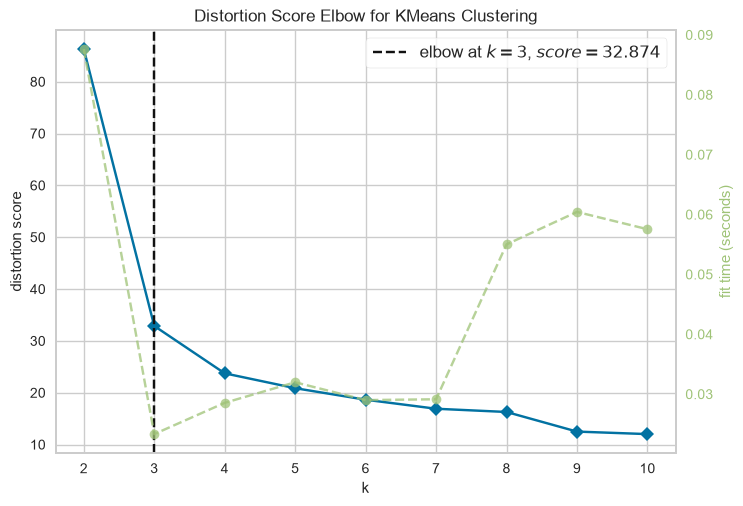

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [14]:
# importer KELbowVisualizer
import setuptools  # charge le module distutils de remplacement pour yellowbrick
from yellowbrick.cluster import KElbowVisualizer

from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init='random', max_iter=500)
kmeans_model._estimator_type = "clusterer"  # contournement : yellowbrick 1.5 + scikit-learn ≥ 1.6
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()


In [15]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 3, init = 'random', max_iter=500, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


#### <font color='teal'> Prédiction

In [16]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[: 100]

array([2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 0, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 1, 2, 2,
       2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2], dtype=int32)

In [17]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

2    2697
1     298
0     155
Name: count, dtype: int64

In [18]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [19]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

In [20]:
# Diagramme en barre des nombres d'observations
bar_plot(val)

In [21]:
# Visualiser les classes
scatter_plot(New_df, kmeans_partition)


##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [22]:
# Silhouette score
from sklearn.metrics import silhouette_score
siil_kmeans = silhouette_score(x, kmeans_partition)
print("Silhouette score for KMeans clustering: ", siil_kmeans)

Silhouette score for KMeans clustering:  0.7848446340351846


### <font color='gold'> CAH

In [23]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

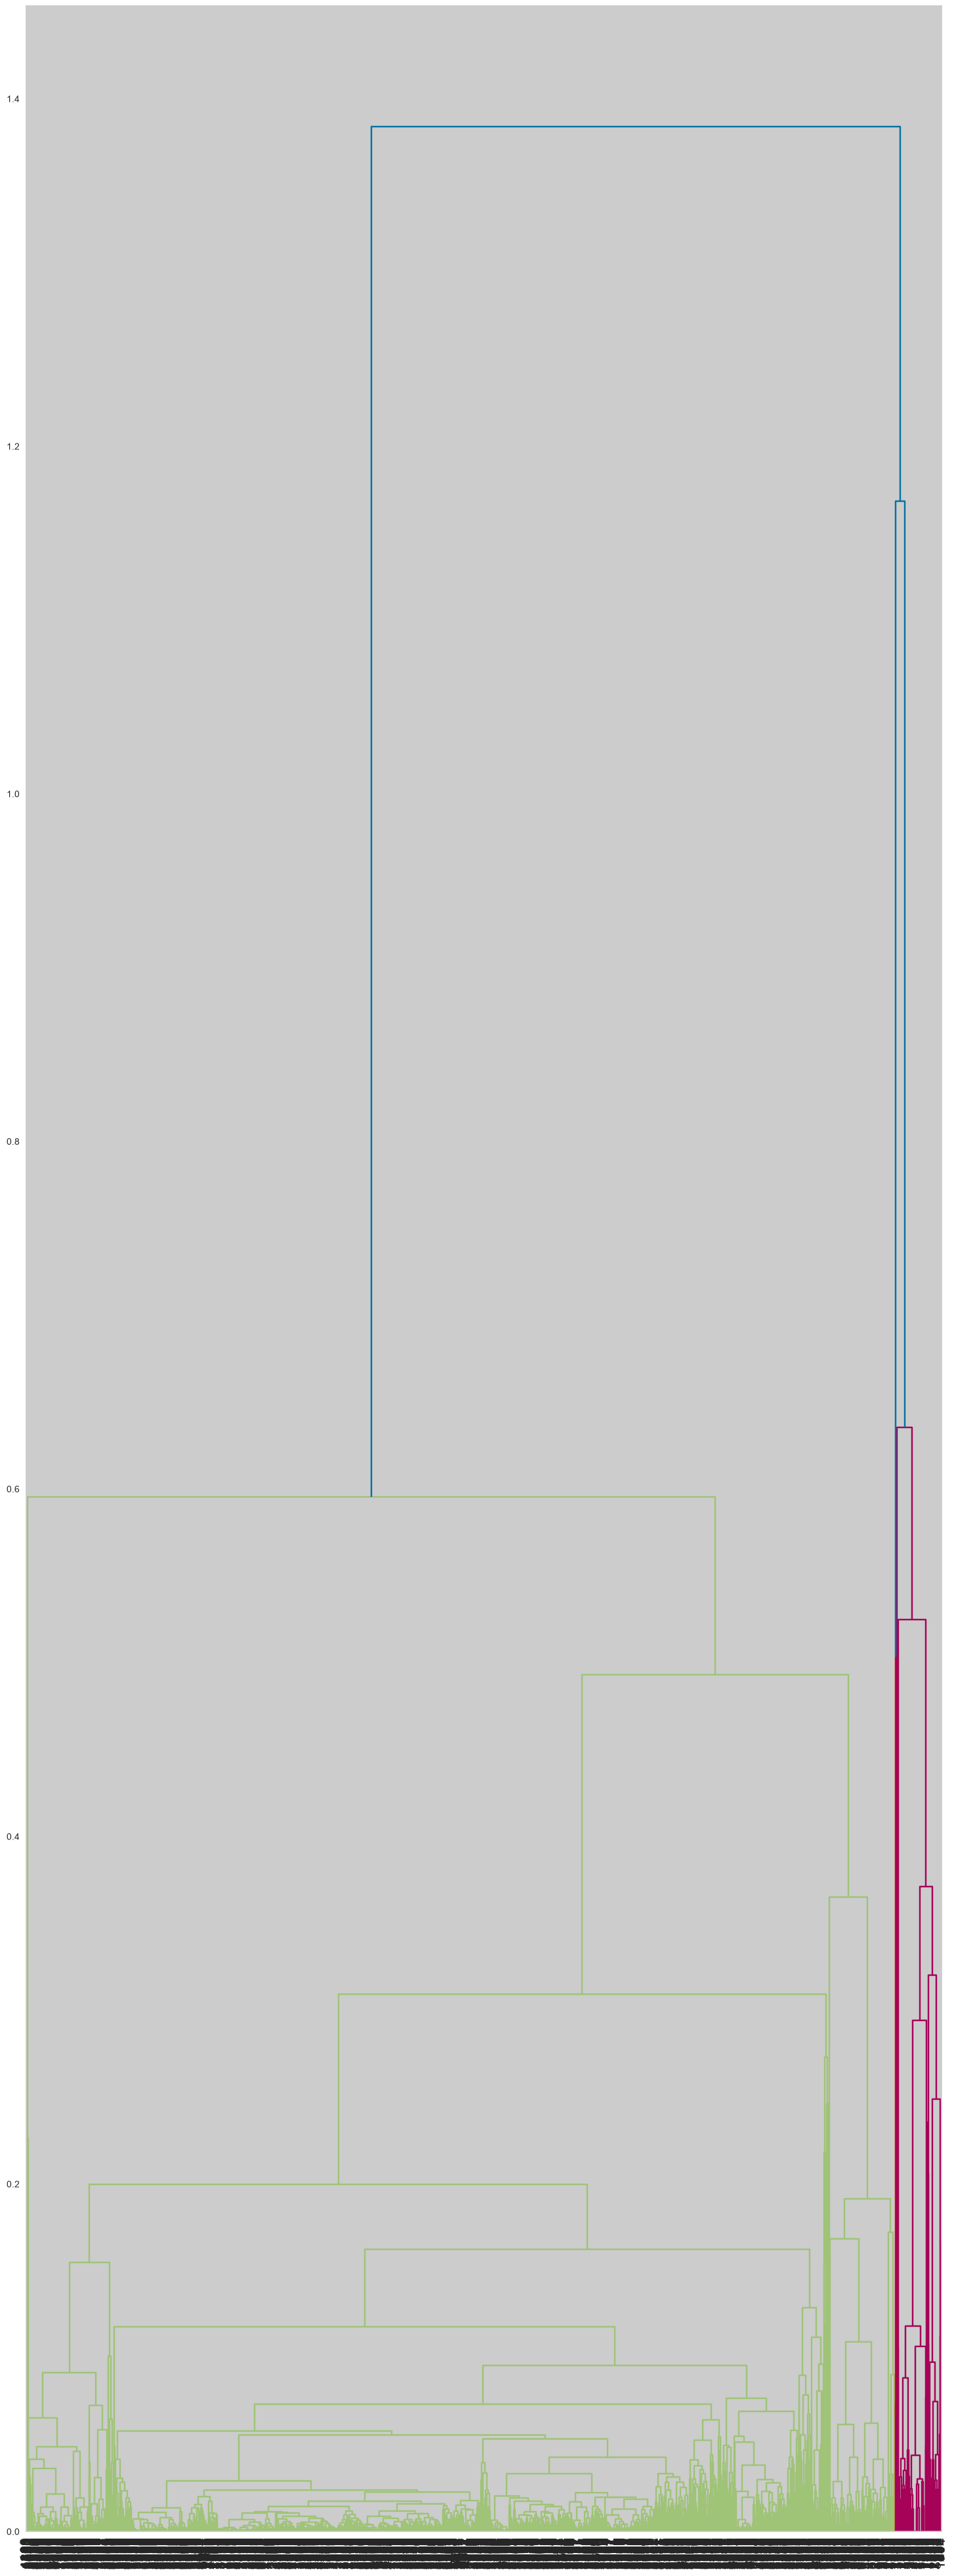

In [24]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [25]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 2, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",2
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'average'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [26]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[: 100]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [27]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

1    2992
0     158
Name: count, dtype: int64

In [28]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [29]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [30]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print("Silhouette score for Agglomerative clustering: ", sil_cah)

Silhouette score for Agglomerative clustering:  0.8852171389623363


In [31]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [siil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [32]:
# les indidivus
cluster_name = []
for i in range(2):  # Assuming 2 clusters
    cluster_name.append(list(df.index[cah_partition == i]))

In [33]:
# Les individus de la classe 0
print("Individus de la classe 0 :")
print(cluster_name[0])

Individus de la classe 0 :
['Client19', 'Client119', 'Client129', 'Client133', 'Client202', 'Client219', 'Client229', 'Client232', 'Client233', 'Client242', 'Client302', 'Client319', 'Client329', 'Client330', 'Client332', 'Client333', 'Client342', 'Client402', 'Client419', 'Client429', 'Client432', 'Client433', 'Client442', 'Client502', 'Client519', 'Client529', 'Client532', 'Client533', 'Client542', 'Client602', 'Client619', 'Client629', 'Client633', 'Client719', 'Client729', 'Client733', 'Client769', 'Client779', 'Client819', 'Client902', 'Client918', 'Client919', 'Client929', 'Client932', 'Client933', 'Client941', 'Client942', 'Client969', 'Client1019', 'Client1052', 'Client1069', 'Client1079', 'Client1083', 'Client1119', 'Client1129', 'Client1152', 'Client1169', 'Client1179', 'Client1183', 'Client1192', 'Client1219', 'Client1229', 'Client1233', 'Client1252', 'Client1269', 'Client1279', 'Client1282', 'Client1283', 'Client1292', 'Client1319', 'Client1352', 'Client1367', 'Client1368',

### <font color='gold'> Déploiement du meilleur modèle (CAH) avec Streamlit

In [34]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau_client):
    client = normalize(np.array(nouveau_client, dtype=float).reshape(1, -1))
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

In [35]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0].values))
print("Classe réelle de la CAH:", cah_partition[0])

Classe prédite  : 1
Classe réelle de la CAH: 1


#### <font color='teal'> Interpréter les classes

Avant de livrer l'application, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [36]:
# Profil moyen de chaque classe (sans les anomalies)
profil = df.groupby(cah_partition).mean().round(2)
profil

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Status,Age,Customer Value
0,0.00,0.10,32.37,0.03,2.24,0.20,2.09,0.11,2.87,1.78,32.75,8.44
1,8.03,0.08,32.55,0.99,4708.52,73.12,76.93,24.75,2.82,1.22,30.91,495.40


In [37]:
# Noms des classes
noms_classes = {
    0: "non fidèle",
    1: "fidèle",
}

In [38]:
# Sauvegarder le modèle de clustering pour l'application Streamlit
# (la PCA sert seulement à visualiser les classes dans le plan PC1, PC2)
import joblib
joblib.dump({'modele': 'CAH', 'variables': list(df.columns), 'classes': classes,
             'centroides': centroides, 'noms_classes': noms_classes, 'pca': pca_model},
            'customer_clustering.joblib')

['customer_clustering.joblib']